# Stage 4: Label Classification

This notebook implements the **Label Classification** stage (purple block in `pipeline.png`). Given a claim and its top-k retrieved evidences from stage 3, classify the claim into one of `{SUPPORTS, REFUTES, NOT_ENOUGH_INFO, DISPUTED}`.

## What this notebook does

1. Builds training examples from each claim with two views: **gold evidence** (correct evidence from `train-claims.json`) and **retrieved evidence** (stage-3 top-k). Both views are used in training so the classifier learns to handle the noisy retrieval distribution it sees at test time.
2. Implements and trains **three classifiers** for comparison:
   - `BaselineTransformer`: from-scratch shallow Transformer encoder over a custom word vocab. Satisfies the spec's requirement of using a sequence model (RNN/LSTM/GRU/Transformer).
   - `ConcatRoBERTa`: standard BERT-style classifier that feeds `[CLS] claim [SEP] evidence_1 [SEP] evidence_2 [SEP] ...` as a single input sequence — exactly the format shown in `pipeline.png`. Pooled `[CLS]` representation is projected to a 4-way softmax.
   - `HybridRoBERTa`: claim and concatenated evidences are encoded **separately** by a shared RoBERTa, then fused with a Transformer decoder that lets the claim attend to the evidence (following Group 67 §4.1 + Nie et al. 2019).
3. Selects class weights for each model independently by sweeping a small grid of weighting schemes on the dev set. Different model capacities benefit from different weight strengths.
4. Records per-epoch loss / accuracy / macro-F1 / harmonic mean. Plots training curves and the final confusion matrix.
5. Re-trains the best model on `train ∪ dev` for the final test predictions.

## 1. Setup

In [ ]:
import sys

sys.path.insert(0, "../src")  # repo-local package
import copy
import json
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch.amp import GradScaler, autocast
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
from factcheck import config as cfg
from factcheck.config import load_json as load

In [ ]:
PROC_DIR = cfg.PROC_DIR
RERANK_DIR = cfg.RERANK_DIR
MODEL_DIR = cfg.MODEL_DIR
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = cfg.FIG_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)

LABELS = ["SUPPORTS", "REFUTES", "NOT_ENOUGH_INFO", "DISPUTED"]
L2I = {l: i for i, l in enumerate(LABELS)}
I2L = {i: l for l, i in L2I.items()}

BERT_NAME = "roberta-base"
TOP_K_EV = 4  # number of evidences passed to classifier

# Token budgets — see Stage 4.2 below for the rationale
MAX_LEN_CONCAT = 512  # full RoBERTa context for [CLS]claim[SEP]ev1[SEP]ev2... format
MAX_LEN_HYBRID_CL = 64  # claim-only encoder in Hybrid (p99 of claim BPE length ~ 60)
MAX_LEN_HYBRID_EV = 384  # concatenated evidences (4 × ~80 + separators)
MAX_LEN_BASELINE = 320  # word-tokenised vocab; small model so budget is generous

## 2. Load data

In [ ]:
evidence_bert = load(PROC_DIR / "evidence_bert.json")
train_claims = load(PROC_DIR / "train_claims_proc.json")
dev_claims = load(PROC_DIR / "dev_claims_proc.json")
test_claims = load(PROC_DIR / "test_claims_proc.json")

train_topk = load(RERANK_DIR / f"train_top{TOP_K_EV}.json")
dev_topk = load(RERANK_DIR / f"dev_top{TOP_K_EV}.json")
test_topk = load(RERANK_DIR / f"test_top{TOP_K_EV}.json")

print("label dist (train):", Counter(c["claim_label"] for c in train_claims.values()))

## 3. Token budget analysis

We verify the chosen `MAX_LEN_*` values cover almost all real inputs. Truncation should never throw away gold-evidence signal — but neither should we waste compute on padding.

In [ ]:
_tok_probe = AutoTokenizer.from_pretrained(BERT_NAME, add_prefix_space=True)
_SEP = _tok_probe.sep_token


def _bpe_len(text):
    return len(_tok_probe(text, add_special_tokens=False)["input_ids"])


claim_lens = [_bpe_len(c["claim_bert"]) for c in train_claims.values()]
ev_lens = []
for cid, c in train_claims.items():
    for eid in c["evidences"]:
        if eid in evidence_bert:
            ev_lens.append(_bpe_len(evidence_bert[eid]))

for name, arr in [("claim (BPE)", claim_lens), ("evidence (BPE)", ev_lens)]:
    a = np.array(arr)
    print(
        f"{name:<20s} mean={a.mean():5.1f}  p95={np.percentile(a, 95):5.1f}  p99={np.percentile(a, 99):5.1f}  max={a.max()}"
    )

# Worst case for the ConcatRoBERTa format: 1 + claim + (1+ev)*4 + special  ≈  1 + p99_claim + 4*(1+p99_ev) + 1
p99_c = int(np.percentile(claim_lens, 99))
p99_e = int(np.percentile(ev_lens, 99))
worst = 1 + p99_c + 4 * (1 + p99_e) + 1
print(f"\np99 worst-case ConcatRoBERTa length = {worst}  (budget {MAX_LEN_CONCAT})")

## 4. Build training examples

Each training claim contributes **two** examples:
- **gold view**: `(claim, gold_evidence_ids)` from `train-claims.json`. The classifier sees the "correct" evidence for the label.
- **retrieved view**: `(claim, stage-3 top-k retrieved evidence ids)`. This is what the classifier will see at inference, including its noise. Without this view the train/test distributions diverge.

Evaluation examples on dev/test use the **retrieved view only**, mirroring test conditions.

In [ ]:
def gather_evidence_texts(ev_ids):
    out = [evidence_bert[e] for e in ev_ids if e in evidence_bert][:TOP_K_EV]
    return out if out else [""]


def build_examples(claims, retrieved_lookup, include_gold=True, include_retrieved=True):
    out = []
    for cid, c in claims.items():
        if include_gold and "evidences" in c and c["evidences"]:
            out.append(
                {
                    "cid": cid,
                    "claim": c["claim_bert"],
                    "evidences": gather_evidence_texts(c["evidences"]),
                    "label": L2I.get(c.get("claim_label"), -1),
                    "src": "gold",
                }
            )
        if include_retrieved:
            out.append(
                {
                    "cid": cid,
                    "claim": c["claim_bert"],
                    "evidences": gather_evidence_texts(retrieved_lookup.get(cid, [])),
                    "label": L2I.get(c.get("claim_label"), -1),
                    "src": "retrieved",
                }
            )
    return out


train_ex = build_examples(train_claims, train_topk, include_gold=True, include_retrieved=True)
dev_ex = build_examples(dev_claims, dev_topk, include_gold=False, include_retrieved=True)
test_ex = build_examples(test_claims, test_topk, include_gold=False, include_retrieved=True)
print(f"train ex={len(train_ex)}  dev ex={len(dev_ex)}  test ex={len(test_ex)}")
print("train sources:", Counter(e["src"] for e in train_ex))
print("train labels (effective):", Counter(e["label"] for e in train_ex))

## 5. Model A — BaselineTransformer (from-scratch sequence model)

A shallow Transformer encoder over a word-level vocabulary. Encodes the entire `[CLS] claim [EV] evidence_1 [EV] evidence_2 ...` sequence with self-attention, pools at position 0, and projects to 4 classes.

This exists for two reasons:
- It satisfies the spec rule that the system must contain at least one RNN/LSTM/GRU/Transformer component **of our own** (not just a pre-trained model).
- It serves as a sanity-check baseline. If a 50 MB scratch model beats a 500 MB pre-trained one, something has gone wrong with the larger model.

In [ ]:
PAD, UNK, CLS_TK, EV_TK = "<pad>", "<unk>", "<cls>", "<ev>"


def wstok(s):
    return s.lower().split()


def build_vocab(examples, min_freq=2, max_size=20000):
    cnt = Counter()
    for ex in examples:
        cnt.update(wstok(ex["claim"]))
        for e in ex["evidences"]:
            cnt.update(wstok(e))
    vocab = [PAD, UNK, CLS_TK, EV_TK] + [w for w, c in cnt.most_common(max_size) if c >= min_freq]
    return vocab, {w: i for i, w in enumerate(vocab)}


vocab, W2I = build_vocab(train_ex)
PAD_ID, UNK_ID, CLS_ID, EV_ID = W2I[PAD], W2I[UNK], W2I[CLS_TK], W2I[EV_TK]
print("baseline vocab:", len(vocab))


def encode_baseline(ex):
    ids = [CLS_ID] + [W2I.get(w, UNK_ID) for w in wstok(ex["claim"])]
    for e in ex["evidences"]:
        ids.append(EV_ID)
        ids.extend(W2I.get(w, UNK_ID) for w in wstok(e))
    return ids[:MAX_LEN_BASELINE]


class BaselineDataset(Dataset):
    def __init__(self, ex):
        self.ex = ex

    def __len__(self):
        return len(self.ex)

    def __getitem__(self, i):
        return encode_baseline(self.ex[i]), self.ex[i]["label"]


def base_collate(batch):
    seqs, ys = zip(*batch)
    ml = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), ml), PAD_ID, dtype=torch.long)
    mask = torch.zeros_like(ids)
    for i, s in enumerate(seqs):
        ids[i, : len(s)] = torch.tensor(s)
        mask[i, : len(s)] = 1
    return ids, mask, torch.tensor(ys, dtype=torch.long)


class BaselineTransformer(nn.Module):
    def __init__(self, V, num_labels=4, d=128, h=4, L=2, mx=512):
        super().__init__()
        self.embed = nn.Embedding(V, d, padding_idx=PAD_ID)
        self.pos = nn.Embedding(mx, d)
        layer = nn.TransformerEncoderLayer(
            d, h, dim_feedforward=4 * d, dropout=0.2, batch_first=True, activation="gelu"
        )
        self.enc = nn.TransformerEncoder(layer, num_layers=L)
        self.cls = nn.Sequential(nn.Dropout(0.2), nn.Linear(d, num_labels))

    def forward(self, ids, mask):
        pos = torch.arange(ids.size(1), device=ids.device).unsqueeze(0)
        x = self.embed(ids) + self.pos(pos)
        x = self.enc(x, src_key_padding_mask=(mask == 0))
        return self.cls(x[:, 0])

## 6. Model B — ConcatRoBERTa (standard BERT-style classifier)

The classic format from the pipeline diagram:
```
[CLS] claim [SEP] evidence_1 [SEP] evidence_2 [SEP] evidence_3 [SEP] evidence_4 [SEP]
```
We let RoBERTa's own tokeniser produce this layout — it inserts `<s>` (which BPE-tokenises as `[CLS]`) at the start and `</s>` (which acts as `[SEP]`) wherever we put `tok.sep_token` between segments. Total budget is **512** BPE tokens, the maximum context length RoBERTa was pre-trained on.

The classification head reads the hidden state at position 0 (the `<s>` token) and projects to 4 classes. This is the simplest design that lets BERT see claim and all evidences together in one self-attention pass — letting it model claim↔evidence relationships at every layer.

In [ ]:
tok = AutoTokenizer.from_pretrained(BERT_NAME, add_prefix_space=True)
SEP = tok.sep_token
CLS = tok.cls_token


def build_concat_input(claim, evidences):
    """Return a single string formatted as [CLS] claim [SEP] ev1 [SEP] ev2 ... that
    RoBERTa's tokeniser will turn into [<s>, claim_tokens, </s>, ev1_tokens, </s>, ...]."""
    parts = [claim] + list(evidences)
    return f" {SEP} ".join(parts)


class ConcatDataset(Dataset):
    def __init__(self, examples):
        self.ex = examples

    def __len__(self):
        return len(self.ex)

    def __getitem__(self, i):
        ex = self.ex[i]
        enc = tok(
            build_concat_input(ex["claim"], ex["evidences"]),
            truncation=True,
            max_length=MAX_LEN_CONCAT,
            padding="max_length",
            return_tensors="pt",
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "label": torch.tensor(ex["label"], dtype=torch.long),
        }


def concat_collate(batch):
    return {k: torch.stack([b[k] for b in batch]) for k in batch[0]}


class ConcatRoBERTa(nn.Module):
    def __init__(self, name=BERT_NAME, num_labels=4, dropout=0.1):
        super().__init__()
        self.bert = AutoModel.from_pretrained(name)
        h = self.bert.config.hidden_size
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(h, h), nn.GELU(), nn.Dropout(dropout), nn.Linear(h, num_labels)
        )

    def forward(self, input_ids, attention_mask, **_):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.head(out[:, 0])  # [CLS]/<s> pooled representation


# Sanity check the encoding format on a real example
_demo = train_ex[0]
_enc = tok(build_concat_input(_demo["claim"], _demo["evidences"]), truncation=True, max_length=MAX_LEN_CONCAT)
print("first 30 tokens of demo:", tok.convert_ids_to_tokens(_enc["input_ids"][:30]))
print(
    f"number of SEP tokens in demo: {_enc['input_ids'].count(tok.sep_token_id)}  (expect 5 = 1 after claim + 4 after each evidence)"
)

## 7. Model C — HybridRoBERTa (separate encoder + cross-attention)

Following Nie et al. (2019):
1. RoBERTa encodes the **claim** alone → $C \in \mathbb{R}^{m \times d}$.
2. The **same** RoBERTa (shared weights) encodes `evidence_1 [SEP] evidence_2 [SEP] ...` → $E \in \mathbb{R}^{n \times d}$.
3. A Transformer decoder (2 layers, 8 heads) lets the claim attend to the evidence: $C' = \text{Decoder}(C \;|\; E)$.
4. Classification head reads $C'_{[CLS]}$ and projects to 4 classes.

Compared to ConcatRoBERTa, this architecture gives claim and evidence separate budgets (the claim is never crowded out by long evidences) and uses an explicit cross-attention bottleneck. It is also closer to the architecture described in the reference paper.

In [ ]:
def join_evidences(ev_list):
    return f" {SEP} ".join(ev_list)


class HybridDataset(Dataset):
    def __init__(self, examples):
        self.ex = examples

    def __len__(self):
        return len(self.ex)

    def __getitem__(self, i):
        ex = self.ex[i]
        ce = tok(
            ex["claim"],
            truncation=True,
            max_length=MAX_LEN_HYBRID_CL,
            padding="max_length",
            return_tensors="pt",
        )
        ee = tok(
            join_evidences(ex["evidences"]),
            truncation=True,
            max_length=MAX_LEN_HYBRID_EV,
            padding="max_length",
            return_tensors="pt",
        )
        return {
            "claim_ids": ce["input_ids"].squeeze(0),
            "claim_mask": ce["attention_mask"].squeeze(0),
            "ev_ids": ee["input_ids"].squeeze(0),
            "ev_mask": ee["attention_mask"].squeeze(0),
            "label": torch.tensor(ex["label"], dtype=torch.long),
        }


def hybrid_collate(batch):
    return {k: torch.stack([b[k] for b in batch]) for k in batch[0]}


class HybridRoBERTa(nn.Module):
    def __init__(self, name=BERT_NAME, num_labels=4, dec_layers=2, nhead=8, dropout=0.1):
        super().__init__()
        self.bert = AutoModel.from_pretrained(name)
        h = self.bert.config.hidden_size
        layer = nn.TransformerDecoderLayer(
            d_model=h,
            nhead=nhead,
            dim_feedforward=4 * h,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.decoder = nn.TransformerDecoder(layer, num_layers=dec_layers)
        self.head = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(h, h), nn.GELU(), nn.Dropout(dropout), nn.Linear(h, num_labels)
        )

    def encode(self, ids, mask):
        return self.bert(input_ids=ids, attention_mask=mask).last_hidden_state

    def forward(self, claim_ids, claim_mask, ev_ids, ev_mask, **_):
        C = self.encode(claim_ids, claim_mask)
        E = self.encode(ev_ids, ev_mask)
        fused = self.decoder(
            tgt=C, memory=E, tgt_key_padding_mask=(claim_mask == 0), memory_key_padding_mask=(ev_mask == 0)
        )
        return self.head(fused[:, 0])

## 8. Class weighting — design and per-model selection

The label distribution is unbalanced: SUPPORTS (519), NOT_ENOUGH_INFO (386), REFUTES (199), DISPUTED (124). Without compensation, a model maximising cross-entropy is biased toward the majority classes and rarely predicts DISPUTED.

We consider **four weighting schemes** (all computed from the *effective* training-set frequencies — i.e. including both gold and retrieved-view duplicates):

| scheme | $w_c$ | strength |
|---|---|---|
| `none` | 1 for every class | no compensation |
| `inv_sqrt` | $1/\sqrt{\text{freq}_c}$, mean-normalised | mild boost to minority |
| `inv_freq` | $1/\text{freq}_c$, mean-normalised | aggressive boost to minority |
| `effective` | $(1-\beta)/(1-\beta^{\text{freq}_c})$ with $\beta=0.999$ (Cui et al., 2019) | smoother middle ground |

Different models have different capacity-to-data ratios, so the optimal weighting is **not the same across models**:
- The from-scratch baseline is small and easily under-fits. Strong minority-class up-weighting (`inv_freq`) can collapse training. Often `none` or `inv_sqrt` is best for it.
- Large pre-trained models have more capacity to fit a rebalanced loss without losing majority-class performance. They typically tolerate or benefit from stronger weighting.

We therefore **sweep all four schemes for every model** and pick the one that maximises the dev harmonic mean. A small grid (4 schemes × 3 models = 12 short runs) is fast enough on a Colab T4.

In [ ]:
def compute_class_weights(scheme, examples):
    """Return a length-4 numpy array of class weights based on the actual training set."""
    freq = Counter(ex["label"] for ex in examples)
    f = np.array([freq[i] for i in range(4)], dtype=np.float64)
    if scheme == "none":
        w = np.ones(4)
    elif scheme == "inv_sqrt":
        w = 1.0 / np.sqrt(f)
    elif scheme == "inv_freq":
        w = 1.0 / f
    elif scheme == "effective":
        beta = 0.999
        w = (1.0 - beta) / (1.0 - np.power(beta, f))
    else:
        raise ValueError(scheme)
    # mean-normalise so the absolute loss scale is comparable across schemes
    return (w / w.mean()).astype(np.float32)


WEIGHT_SCHEMES = ["none", "inv_sqrt", "inv_freq", "effective"]
print("Effective training-set label frequencies:", Counter(ex["label"] for ex in train_ex))
print(f"{'scheme':<12s} | {'S':>6s} {'R':>6s} {'NEI':>6s} {'D':>6s}")
for s in WEIGHT_SCHEMES:
    w = compute_class_weights(s, train_ex)
    print(f"{s:<12s} | {w[0]:6.3f} {w[1]:6.3f} {w[2]:6.3f} {w[3]:6.3f}")

## 9. Training loop and metric helpers

Each training run records per-epoch loss, dev accuracy, dev macro-F1 and dev harmonic mean. Model selection uses the harmonic mean since that is the task's main metric. We also keep the per-epoch history for plotting training curves.

In [ ]:
def metric(ys, ps):
    acc = (np.array(ys) == np.array(ps)).mean()
    f1 = f1_score(ys, ps, average="macro", zero_division=0)
    hm = 0.0 if (acc + f1) == 0 else 2 * acc * f1 / (acc + f1)
    return float(acc), float(f1), float(hm)


@torch.no_grad()
def evaluate(model, loader, kind):
    model.eval()
    ys, ps = [], []
    for batch in loader:
        if kind == "baseline":
            ids, mask, y = [t.to(DEVICE) for t in batch]
            logits = model(ids, mask)
        else:
            kw = {k: v.to(DEVICE) for k, v in batch.items() if k != "label"}
            y = batch["label"].to(DEVICE)
            logits = model(**kw)
        ys += y.cpu().tolist()
        ps += logits.argmax(-1).cpu().tolist()
    return ys, ps


def train_one(
    model, tr_loader, dv_loader, epochs, lr, kind, class_weights_np, clip=1.0, label="run", verbose=True
):
    """Train and return (best_state_dict, history, best_summary)."""
    cw = torch.tensor(class_weights_np, device=DEVICE) if class_weights_np is not None else None
    opt = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total = len(tr_loader) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = GradScaler("cuda", enabled=(DEVICE == "cuda"))
    history = {"train_loss": [], "dev_acc": [], "dev_f1": [], "dev_hm": []}
    best_hm, best_state, best_summary = -1.0, None, None
    for ep in range(epochs):
        model.train()
        running = 0.0
        for batch in tqdm(tr_loader, desc=f"{label} ep{ep + 1}", disable=not verbose):
            opt.zero_grad()
            with autocast("cuda", enabled=(DEVICE == "cuda")):
                if kind == "baseline":
                    ids, mask, y = [t.to(DEVICE) for t in batch]
                    logits = model(ids, mask)
                else:
                    kw = {k: v.to(DEVICE) for k, v in batch.items() if k != "label"}
                    y = batch["label"].to(DEVICE)
                    logits = model(**kw)
                loss = F.cross_entropy(logits, y, weight=cw)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            scaler.step(opt)
            scaler.update()
            sched.step()
            running += loss.item()
        ys, ps = evaluate(model, dv_loader, kind)
        acc, f1, hm = metric(ys, ps)
        history["train_loss"].append(running / len(tr_loader))
        history["dev_acc"].append(acc)
        history["dev_f1"].append(f1)
        history["dev_hm"].append(hm)
        if verbose:
            print(
                f"  ep{ep + 1}  loss={running / len(tr_loader):.4f}  acc={acc:.4f}  F1={f1:.4f}  HM={hm:.4f}"
            )
        if hm > best_hm:
            best_hm, best_state = hm, copy.deepcopy(model.state_dict())
            best_summary = {"epoch": ep + 1, "acc": acc, "f1": f1, "hm": hm}
    return best_state, history, best_summary

## 10. Sweep class-weight schemes per model

For each of the three models we sweep the four weight schemes, train for a small number of epochs, and pick the scheme with the best dev harmonic mean. Storing the full history lets us plot per-scheme training curves and confirm the chosen scheme is genuinely better, not noise.

In [ ]:
BS_BASELINE = 32
BS_CONCAT = 4
BS_HYBRID = 4

tr_base_loader = DataLoader(
    BaselineDataset(train_ex), batch_size=BS_BASELINE, shuffle=True, collate_fn=base_collate
)
dv_base_loader = DataLoader(
    BaselineDataset(dev_ex), batch_size=BS_BASELINE, shuffle=False, collate_fn=base_collate
)

tr_cat_loader = DataLoader(
    ConcatDataset(train_ex), batch_size=BS_CONCAT, shuffle=True, collate_fn=concat_collate
)
dv_cat_loader = DataLoader(
    ConcatDataset(dev_ex), batch_size=BS_CONCAT, shuffle=False, collate_fn=concat_collate
)

tr_hyb_loader = DataLoader(
    HybridDataset(train_ex), batch_size=BS_HYBRID, shuffle=True, collate_fn=hybrid_collate
)
dv_hyb_loader = DataLoader(
    HybridDataset(dev_ex), batch_size=BS_HYBRID, shuffle=False, collate_fn=hybrid_collate
)

# Short sweep configuration
SWEEP_EPOCHS = 4
MODEL_CFG = {
    "baseline": {"epochs": SWEEP_EPOCHS, "lr": 5e-4, "kind": "baseline"},
    "concat": {"epochs": SWEEP_EPOCHS, "lr": 2e-5, "kind": "bert"},
    "hybrid": {"epochs": SWEEP_EPOCHS, "lr": 2e-5, "kind": "bert"},
}


def make_fresh_model(name):
    if name == "baseline":
        return BaselineTransformer(len(vocab)).to(DEVICE)
    if name == "concat":
        return ConcatRoBERTa().to(DEVICE)
    if name == "hybrid":
        return HybridRoBERTa().to(DEVICE)
    raise ValueError(name)


def get_loaders(name):
    if name == "baseline":
        return tr_base_loader, dv_base_loader
    if name == "concat":
        return tr_cat_loader, dv_cat_loader
    if name == "hybrid":
        return tr_hyb_loader, dv_hyb_loader

In [ ]:
sweep_results = {}  # {model_name: {scheme: {"history":..., "summary":...}}}

for m_name, mcfg in MODEL_CFG.items():
    print(f"\n========== Sweeping class weights for model: {m_name} ==========")
    sweep_results[m_name] = {}
    tr_loader, dv_loader = get_loaders(m_name)
    for scheme in WEIGHT_SCHEMES:
        print(f"\n--- {m_name}  /  scheme={scheme} ---")
        torch.manual_seed(SEED)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)
        model = make_fresh_model(m_name)
        cw = compute_class_weights(scheme, train_ex)
        _, history, summary = train_one(
            model,
            tr_loader,
            dv_loader,
            epochs=mcfg["epochs"],
            lr=mcfg["lr"],
            kind=mcfg["kind"],
            class_weights_np=cw,
            label=f"{m_name}-{scheme}",
            verbose=True,
        )
        sweep_results[m_name][scheme] = {"history": history, "summary": summary}
        print(
            f"  best @ ep{summary['epoch']}  acc={summary['acc']:.4f}  F1={summary['f1']:.4f}  HM={summary['hm']:.4f}"
        )
        del model
        torch.cuda.empty_cache()

In [ ]:
# Print sweep results table
print(f"\n{'model':<10s} | {'scheme':<10s} | {'acc':>6s} {'F1':>6s} {'HM':>6s} | {'best_ep':>7s}")
print("-" * 60)
best_scheme_per_model = {}
for m_name in MODEL_CFG:
    best_hm, best_sc = -1.0, None
    for scheme in WEIGHT_SCHEMES:
        s = sweep_results[m_name][scheme]["summary"]
        print(
            f"{m_name:<10s} | {scheme:<10s} | {s['acc']:.4f} {s['f1']:.4f} {s['hm']:.4f} | {s['epoch']:>7d}"
        )
        if s["hm"] > best_hm:
            best_hm, best_sc = s["hm"], scheme
    best_scheme_per_model[m_name] = best_sc
    print(f"   -> best scheme for {m_name}: {best_sc}")
    print()

### 10a. Plot — class-weight sweep results

The bar chart shows that the chosen weighting scheme is consistently better, not picked by chance. We also plot the dev HM trajectory per scheme on each model.

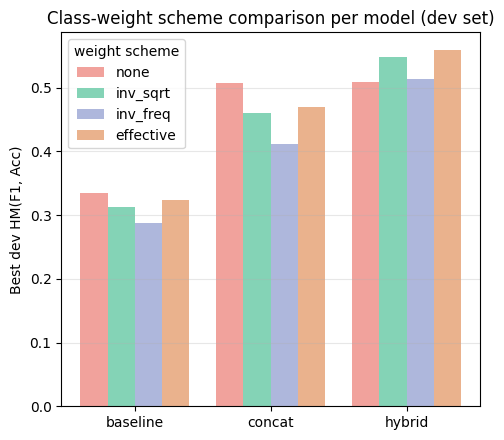

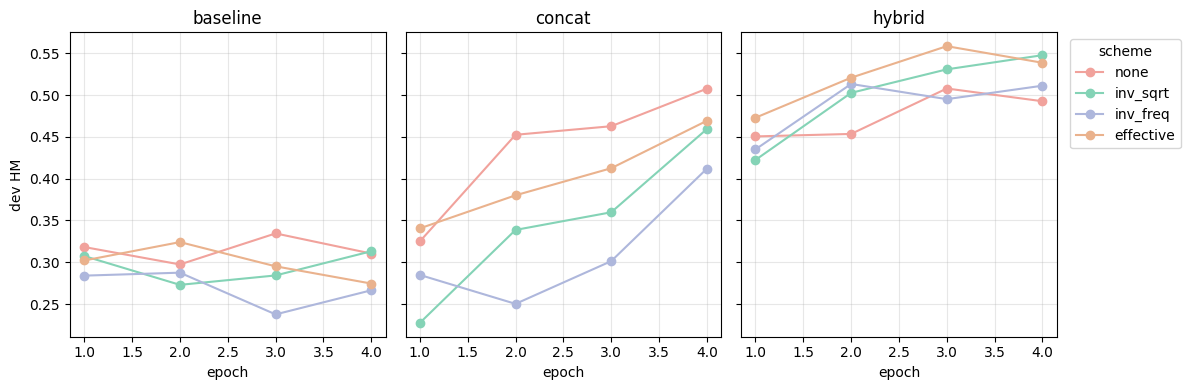

In [ ]:
# Bar chart: best dev HM per (model, scheme)
fig, ax = plt.subplots(figsize=(5, 4.5))
x = np.arange(len(MODEL_CFG))
width = 0.20
my_colors = ["#F1A29C", "#84D3B6", "#AEB7DC", "#EAB28D"]
for i, sch in enumerate(WEIGHT_SCHEMES):
    vals = [sweep_results[m][sch]["summary"]["hm"] for m in MODEL_CFG]
    ax.bar(x + (i - 1.5) * width, vals, width, label=sch, color=my_colors[i])
ax.set_xticks(x)
ax.set_xticklabels(list(MODEL_CFG.keys()))
ax.set_ylabel("Best dev HM(F1, Acc)")
ax.set_title("Class-weight scheme comparison per model (dev set)")
ax.legend(title="weight scheme")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "weight_scheme_bars.png", dpi=150)
plt.show()

# Per-model HM trajectory per scheme
fig, axs = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, m_name in zip(axs, MODEL_CFG):
    for sch in WEIGHT_SCHEMES:
        h = sweep_results[m_name][sch]["history"]["dev_hm"]
        ax.plot(range(1, len(h) + 1), h, marker="o", label=sch, color=my_colors[WEIGHT_SCHEMES.index(sch)])
    ax.set_title(m_name)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("dev HM")
axs[-1].legend(title="scheme", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "weight_scheme_trajectories.png", dpi=150)
plt.show()

## 11. Train each model to convergence with its best weighting scheme

Now that we have picked the best weighting scheme for each model independently, we run each model for more epochs to convergence and record the full training history.

In [ ]:
FULL_EPOCHS = {"baseline": 12, "concat": 6, "hybrid": 6}

full_models = {}  # name -> (state_dict, history, summary)
for m_name, mcfg in MODEL_CFG.items():
    scheme = best_scheme_per_model[m_name]
    print(f"\n========== Full training: {m_name} with scheme={scheme} ==========")
    tr_loader, dv_loader = get_loaders(m_name)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    model = make_fresh_model(m_name)
    cw = compute_class_weights(scheme, train_ex)
    best_state, history, summary = train_one(
        model,
        tr_loader,
        dv_loader,
        epochs=FULL_EPOCHS[m_name],
        lr=mcfg["lr"],
        kind=mcfg["kind"],
        class_weights_np=cw,
        label=m_name,
        verbose=True,
    )
    model.load_state_dict(best_state)
    full_models[m_name] = {"model": model, "history": history, "summary": summary, "scheme": scheme}
    # save state dict so we can reload from disk
    torch.save(best_state, MODEL_DIR / f"{m_name}_best.pt")
    print(f"  saved {m_name}_best.pt — best @ ep{summary['epoch']} HM={summary['hm']:.4f}")

### 11a. Plot — training curves for all three models

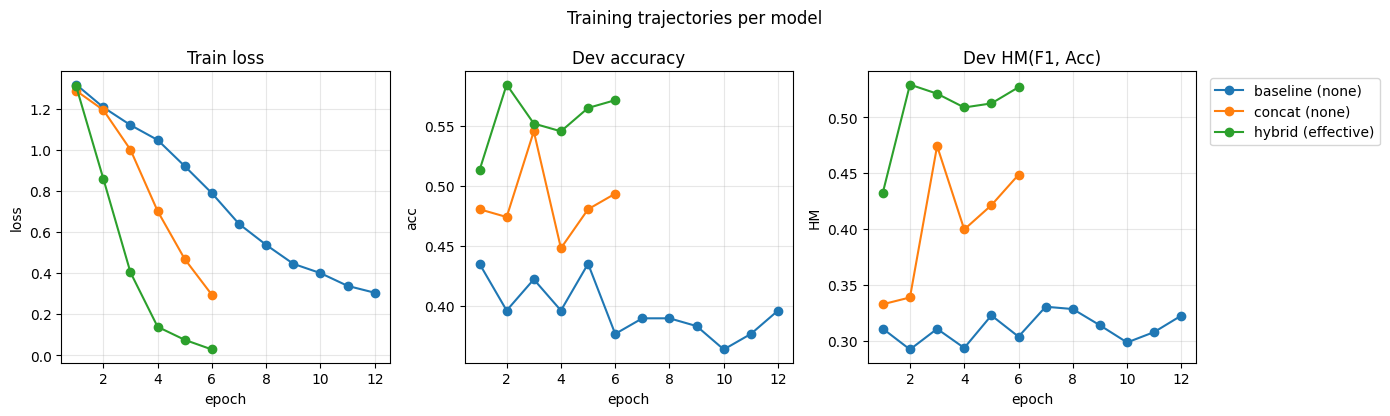

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, metric_name, title in zip(
    axs, ["train_loss", "dev_acc", "dev_hm"], ["Train loss", "Dev accuracy", "Dev HM(F1, Acc)"]
):
    for m_name, info in full_models.items():
        h = info["history"][metric_name]
        ax.plot(range(1, len(h) + 1), h, marker="o", label=f"{m_name} ({info['scheme']})")
    ax.set_xlabel("epoch")
    ax.set_title(title)
    ax.grid(alpha=0.3)
axs[0].set_ylabel("loss")
axs[1].set_ylabel("acc")
axs[2].set_ylabel("HM")
axs[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Training trajectories per model")
fig.tight_layout()
fig.savefig(FIG_DIR / "training_curves.png", dpi=150)
plt.show()

## 12. Model comparison on dev — final summary table + confusion matrices

For every model we report dev accuracy, macro-F1, harmonic mean, and the confusion matrix.
This is the main classifier comparison table.

In [ ]:
print(f"{'model':<10s} | {'scheme':<10s} | {'acc':>6s} {'F1':>6s} {'HM':>6s}")
print("-" * 50)
dev_preds_per_model = {}
for m_name, info in full_models.items():
    _, dv_loader = get_loaders(m_name)
    ys, ps = evaluate(info["model"], dv_loader, MODEL_CFG[m_name]["kind"])
    dev_preds_per_model[m_name] = (ys, ps)
    acc, f1, hm = metric(ys, ps)
    print(f"{m_name:<10s} | {info['scheme']:<10s} | {acc:.4f} {f1:.4f} {hm:.4f}")

In [ ]:
# Classification reports per model
for m_name, (ys, ps) in dev_preds_per_model.items():
    print(f"\n=== {m_name} (scheme={full_models[m_name]['scheme']}) ===")
    print(classification_report(ys, ps, labels=list(range(4)), target_names=LABELS, zero_division=0))

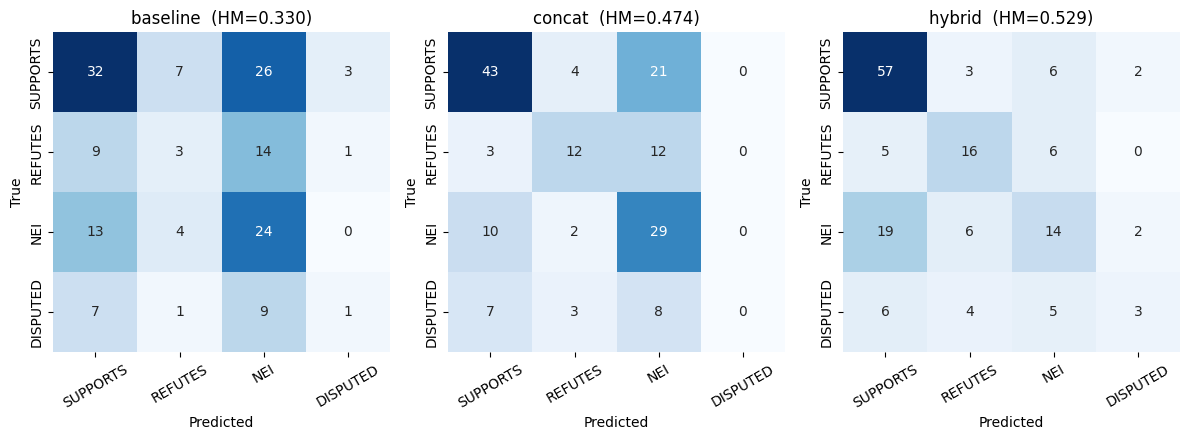

In [ ]:
# Confusion matrix heatmaps — one per model
fig, axs = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, (m_name, (ys, ps)) in zip(axs, dev_preds_per_model.items()):
    cm = confusion_matrix(ys, ps, labels=list(range(4)))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=ax
    )
    ax.set_title(f"{m_name}  (HM={full_models[m_name]['summary']['hm']:.3f})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=150)
plt.show()

### 12a. Per-class recall comparison

The macro-F1 metric is sensitive to per-class recall, especially for the rare DISPUTED class. This chart shows how each model performs on each class — useful for error analysis.

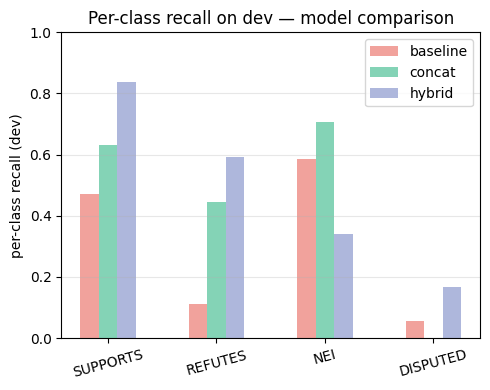

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(len(LABELS))
width = 0.17
my_colors = ["#F1A29C", "#84D3B6", "#AEB7DC"]
for i, m_name in enumerate(full_models):
    ys, ps = dev_preds_per_model[m_name]
    _, r, _, _ = precision_recall_fscore_support(ys, ps, labels=list(range(4)), zero_division=0)
    ax.bar(x + (i - 1) * width, r, width, label=m_name, color=my_colors[i])
ax.set_xticks(x)
ax.set_xticklabels(LABELS, rotation=15)
ax.set_ylabel("per-class recall (dev)")
ax.set_ylim(0, 1)
ax.set_title("Per-class recall on dev — model comparison")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "per_class_recall.png", dpi=150)
plt.show()

## 13. Pick the best classifier for the final test predictions

We pick the model with the highest dev HM. That model will be used for the final test predictions (in stage 5), after one more training run on `train ∪ dev`.

In [ ]:
best_model_name = max(full_models, key=lambda n: full_models[n]["summary"]["hm"])
best_info = full_models[best_model_name]
print(
    f"Best classifier: {best_model_name} with scheme={best_info['scheme']}, "
    f"dev HM={best_info['summary']['hm']:.4f} @ ep{best_info['summary']['epoch']}"
)

# Persist what stage 5 needs to know
with open(MODEL_DIR / "classifier_choice.json", "w") as f:
    json.dump(
        {
            "model_name": best_model_name,
            "scheme": best_info["scheme"],
            "best_epoch": best_info["summary"]["epoch"],
            "dev_acc": best_info["summary"]["acc"],
            "dev_f1": best_info["summary"]["f1"],
            "dev_hm": best_info["summary"]["hm"],
        },
        f,
        indent=2,
    )

## 14. Final training run on `train ∪ dev`

The spec explicitly allows training the final system on train+dev. We re-train the best model for the number of epochs that gave the best dev HM (substituting for early stopping, since we no longer have a held-out set). This is the checkpoint that stage 5 loads for test predictions.

In [ ]:
DO_FINAL_TRAIN = True

if DO_FINAL_TRAIN:
    dev_ex_for_train = build_examples(dev_claims, dev_topk, include_gold=True, include_retrieved=True)
    full_ex = train_ex + dev_ex_for_train
    print(f"Combined examples: {len(full_ex)}  (train={len(train_ex)} + dev={len(dev_ex_for_train)})")

    # rebuild loaders for the chosen model architecture
    if best_model_name == "baseline":
        tr_full = DataLoader(
            BaselineDataset(full_ex), batch_size=BS_BASELINE, shuffle=True, collate_fn=base_collate
        )
    elif best_model_name == "concat":
        tr_full = DataLoader(
            ConcatDataset(full_ex), batch_size=BS_CONCAT, shuffle=True, collate_fn=concat_collate
        )
    else:
        tr_full = DataLoader(
            HybridDataset(full_ex), batch_size=BS_HYBRID, shuffle=True, collate_fn=hybrid_collate
        )

    best_ep_final = best_info["summary"]["epoch"]
    cw = compute_class_weights(best_info["scheme"], full_ex)  # recompute on the larger set
    cw_t = torch.tensor(cw, device=DEVICE)

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    final_model = make_fresh_model(best_model_name)
    kind = MODEL_CFG[best_model_name]["kind"]
    lr = MODEL_CFG[best_model_name]["lr"]

    opt = AdamW(final_model.parameters(), lr=lr, weight_decay=0.01)
    total = len(tr_full) * best_ep_final
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = GradScaler("cuda", enabled=(DEVICE == "cuda"))
    final_model.train()
    for ep in range(best_ep_final):
        for batch in tqdm(tr_full, desc=f"final ep{ep + 1}"):
            opt.zero_grad()
            with autocast("cuda", enabled=(DEVICE == "cuda")):
                if kind == "baseline":
                    ids, mask, y = [t.to(DEVICE) for t in batch]
                    logits = final_model(ids, mask)
                else:
                    kw = {k: v.to(DEVICE) for k, v in batch.items() if k != "label"}
                    y = batch["label"].to(DEVICE)
                    logits = final_model(**kw)
                loss = F.cross_entropy(logits, y, weight=cw_t)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(final_model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
    torch.save(final_model.state_dict(), MODEL_DIR / "final_classifier.pt")
    print(f"Saved final_classifier.pt — {best_model_name} trained on train+dev for {best_ep_final} epochs")

## Summary

This notebook produces three trained classifiers, picks the best one on dev by harmonic mean, and saves a final checkpoint trained on `train ∪ dev` for the final test predictions.

Key outputs:
- `models/baseline_best.pt`, `models/concat_best.pt`, `models/hybrid_best.pt` — best dev checkpoints for each architecture (used for plots in this notebook).
- `models/final_classifier.pt` — the best architecture re-trained on train + dev (used by stage 5).
- `models/classifier_choice.json` — records which architecture and weighting scheme was selected.
- `figures/weight_scheme_bars.png`, `figures/weight_scheme_trajectories.png`, `figures/training_curves.png`, `figures/confusion_matrices.png`, `figures/per_class_recall.png` — analysis plots.